# Empleo en sectores de alta tecnología

In [ ]:
# Parámetros de la gráfica
SLUG = "economia"               # carpeta en research/temas/
GRAFICA_ID = "empleo-sectores-alta-tecnologia"  # id de la gráfica (kebab-case) = nombre del notebook
TITULO = "Empleo en sectores de alta tecnología"  # `titulo` de la gráfica en config.json
DESDE = 1976                    # inicio de la ventana temporal (METODOLOGIA §2.3)
TIPO = "serie_temporal"         # serie_temporal | por_ccaa | solo_espana
VISTA = "lineas"  # `vista` de la gráfica en config.json: lineas | ultimo_anio | proyeccion | categorias
EJE_MAX = None  # `eje_max` de la gráfica en config.json; None = el que piden los datos
UNIDAD = "% del empleo total"
CSV_FORMATO = "es"              # CSV: "es" (separador ; y coma decimal, Excel en español) o "int" (, y punto)
CSV_DECIMALES = 1               # decimales del CSV (el JSON guarda el valor completo)
REFERENCIA = None               # línea horizontal de referencia (p. ej. 100 en un índice); None = sin línea
DIR_SALIDA = None               # solo tests; None = temas/<SLUG>/data/

## 1. Contexto

**Qué mide.** El porcentaje de las personas ocupadas que trabajan en **sectores de alta tecnología**, según la clasificación oficial de Eurostat (basada en la intensidad de I+D de cada actividad): la **industria de alta tecnología** (farmacia, productos informáticos y electrónicos, aeronáutica) y los **servicios intensivos en conocimiento de alta tecnología** (telecomunicaciones, programación y servicios de información, cine y edición, investigación y desarrollo).

**Para qué sirve.** Es una forma de ver la estructura productiva: cuánto empleo hay en las actividades que más invierten en investigación y que suelen tener una productividad alta. Complementa la gráfica del empleo en empresas de baja productividad.

**Limitaciones.**
- La clasificación es por actividad, no por empresa: una empresa muy innovadora de un sector tradicional no cuenta, y una poco innovadora de un sector de alta tecnología sí.
- No incluye los servicios financieros ni las actividades profesionales y científicas (salvo la I+D), que Eurostat clasifica como intensivos en conocimiento pero no de alta tecnología.
- Mide empleo, no producción: el peso de estos sectores en el valor añadido solo se publica hasta 2014 (`htec_eco_sbs2`) y no se usa.
- Solo España y la UE-27 (encuesta de población activa de la UE); la OCDE no publica el mismo agregado.

## 2. Descarga

**Eurostat, empleo en sectores de tecnología y conocimiento** (`htec_emp_nat2`, a partir de la encuesta de población activa de la UE, NACE Rev. 2, desde 2008): personas ocupadas en sectores de alta tecnología (`HTC`) en % del empleo total (`PC_EMP`), ambos sexos, de España y la UE-27; para las notas, la industria de tecnología alta y media-alta (`C_HTC_MH`) y los servicios de alta tecnología (`KIS_HTC`).

In [ ]:
import sys
from pathlib import Path

# Raíz del proyecto (la carpeta con global.json y lib/), buscando hacia arriba desde el directorio de ejecución
RAIZ = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "global.json").exists()), None)
if RAIZ is None:
    raise FileNotFoundError(
        "No se encuentra global.json. Abre el notebook desde su carpeta (temas/<tema>/notebooks/) "
        "dentro del repositorio completo; consulta el README para instalar el entorno."
    )
sys.path.insert(0, str(RAIZ))

from datetime import date

import pandas as pd

from lib import estilos, eurostat
from lib.tipos import FuenteMeta
from lib.writer import construir_grafica_data, write_grafica_data

HOY = date.today().isoformat()
FILTROS = {"freq": "A", "sex": "T", "unit": "PC_EMP"}

df, fuentes = eurostat.get("htec_emp_nat2", {**FILTROS, "nace_r2": "HTC"}, desde=DESDE)
estados, etiquetas = eurostat.get_estados("htec_emp_nat2", {**FILTROS, "nace_r2": "HTC"}, desde=DESDE)
partes = {n: eurostat.get("htec_emp_nat2", {**FILTROS, "nace_r2": n}, desde=DESDE)[0].set_index(["serie", "periodo"])["valor"]
          for n in ("C_HTC_MH", "KIS_HTC", "C_HTC")}
print(df.groupby("serie")["periodo"].agg(["min", "max", "count"]))
print("Marcas:", estados.drop_duplicates("estado").to_string(index=False), etiquetas)

         min   max  count
serie                    
espana  2008  2025     18
ue27    2008  2025     18
Marcas:  serie  periodo estado
espana     2008      b
espana     2021     bd
espana     2022      d {'b': 'break in time series', 'bd': 'break in time series, definition differs (see metadata)', 'd': 'definition differs (see metadata)'}


## 3. Transformación

1. Los porcentajes se usan tal como los publica Eurostat, sin transformar.
2. Las series `ocde`, `eeuu` y `canada` quedan en `null`: el agregado es de Eurostat.
3. Para las notas: el reparto entre industria y servicios de alta tecnología en España y la UE-27 en el último año, y las rupturas de serie que marca Eurostat.

In [ ]:
def es(v, d=1):
    return estilos.formato_es(v, d)


vacias = pd.DataFrame({"serie": ["ocde", "eeuu", "canada"], "periodo": [DESDE] * 3, "valor": [float("nan")] * 3})
df = pd.concat([df, vacias], ignore_index=True)
fuentes = [*fuentes, *[FuenteMeta(s, eurostat.ORGANISMO, "sin dato: htec_emp_nat2 solo cubre Europa",
                                  eurostat.URL_DATABROWSER.format(dataset="htec_emp_nat2"), HOY) for s in ("ocde", "eeuu", "canada")]]

a = int(df[df["serie"] == "espana"].dropna()["periodo"].max())
def parte(n, s):
    return es(partes[n].get((s, a)))
rupturas = sorted(estados.loc[(estados["serie"] == "espana") & estados["estado"].str.contains("b"), "periodo"].astype(int))
rupturas = [r for r in rupturas if r > 2008]  # la marca de 2008 solo indica el inicio de la serie
NOTAS = [
    "Eurostat, empleo en sectores de tecnología y conocimiento (htec_emp_nat2), a partir de la encuesta de población "
    "activa de la UE: personas ocupadas en sectores de alta tecnología (HTC: industria de alta tecnología y servicios "
    "intensivos en conocimiento de alta tecnología, divisiones C21, C26, C30.3, J59-J63 y M72 de la NACE Rev. 2) en % "
    "del empleo total.",
    f"En {a}, en España: industria de alta tecnología {parte('C_HTC', 'espana')} % y servicios de alta tecnología "
    f"{parte('KIS_HTC', 'espana')} % del empleo; en la UE-27, {parte('C_HTC', 'ue27')} % y {parte('KIS_HTC', 'ue27')} %. "
    f"Con la industria de tecnología media-alta (química, maquinaria, automóvil), la industria de tecnología alta y "
    f"media-alta suma el {parte('C_HTC_MH', 'espana')} % del empleo en España y el {parte('C_HTC_MH', 'ue27')} % en la UE-27.",
    "La serie con la NACE Rev. 2 empieza en 2008; la anterior (htec_emp_nat, NACE Rev. 1.1) no es comparable y no se usa.",
    "OCDE, Estados Unidos y Canadá: sin dato; la OCDE no publica el mismo agregado de sectores de alta tecnología.",
]
if rupturas:
    NOTAS.append("Eurostat marca ruptura de serie en España en " + ", ".join(map(str, rupturas))
                 + ": en 2021 cambió el reglamento de la encuesta de población activa de la UE.")

## 4. Visualización

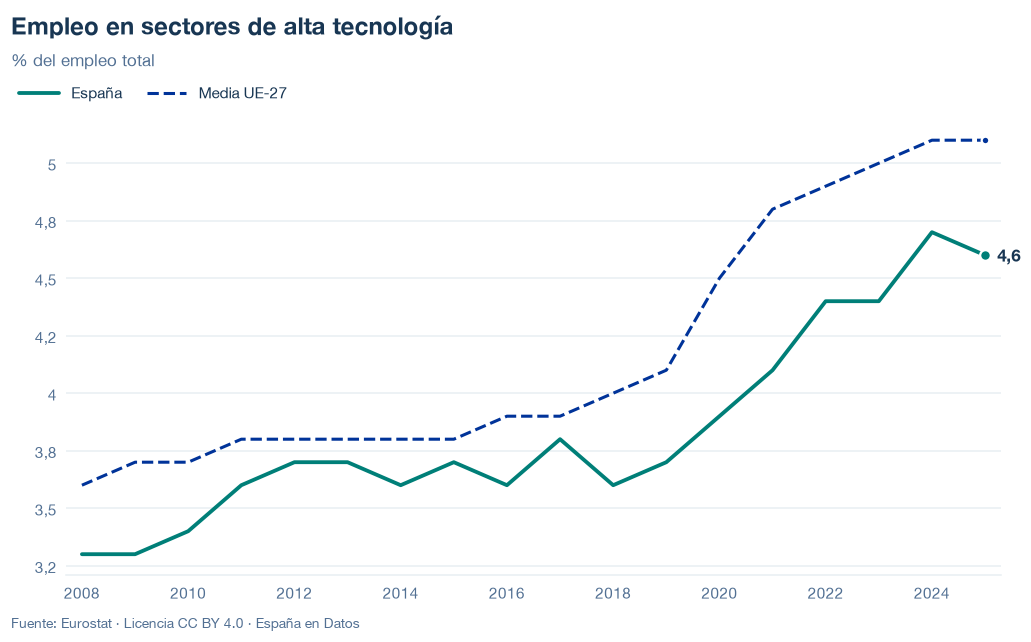

In [ ]:
datos = construir_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
)
fig = estilos.figura(datos, titulo=TITULO, vista=VISTA, eje_max=EJE_MAX)
estilos.mostrar(fig)

## 5. Exportación

Escribe `data/<id>.json` (validado contra el esquema) y `data/<id>.csv`, el mismo CSV que se descarga en la web.

In [ ]:
salida = Path(DIR_SALIDA) if DIR_SALIDA else RAIZ / "temas" / SLUG / "data"
ruta = write_grafica_data(
    df, fuentes, id=GRAFICA_ID, tipo=TIPO, unidad=UNIDAD, notas=NOTAS,
    generado_por=f"temas/{SLUG}/notebooks/{GRAFICA_ID}.ipynb", desde=DESDE, referencia=REFERENCIA,
    path=salida / f"{GRAFICA_ID}.json", csv_formato=CSV_FORMATO, csv_decimales=CSV_DECIMALES,
)
print(f"escrito: data/{ruta.name} y data/{ruta.stem}.csv")  # sin rutas locales en las salidas publicadas

escrito: data/empleo-sectores-alta-tecnologia.json y data/empleo-sectores-alta-tecnologia.csv


## 6. Fuentes, notas y licencia

- Eurostat, `htec_emp_nat2` (`HTC`, `PC_EMP`, `T`; `C_HTC`, `C_HTC_MH` y `KIS_HTC` para las notas).

La fecha de consulta de cada serie está en `fuentes` del JSON; `writer.py` añade a las notas el primer año con dato de cada serie.

**Licencia:** datos, gráficos y textos CC BY 4.0; código MIT. Cita a España en Datos.